# Reinforcement Learning: Using Policy Gradient to solve a Maze

This does not even use a neural network, but instead the policy is stored in an array (table-based policy gradient).

Example code for the lecture series "Machine Learning for Physicists" by Florian Marquardt

Lecture 7, Tutorial (this is discussed in session 7)

See https://machine-learning-for-physicists.org and the current course website linked there!

This notebook is distributed under the Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) license:

https://creativecommons.org/licenses/by-sa/4.0/

This notebook shows how to:
- use policy gradient reinforcement learning to solve a given (fixed) maze (policy gradient based on a table, i.e. state space is sufficiently small)


A little robot is sent through a maze, to collect treasure chests. The maze and the distribution of treasure chests are fixed (i.e. in every trial the robot encounters the same maze).

Will it be able to find the best strategy?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib
matplotlib.rcParams['figure.dpi']=300 # highres display

# for subplots within subplots:
from matplotlib import gridspec

from IPython.display import clear_output
from time import sleep

## Maze generation algorithm

In [ ]:
# Maze generation algorithm from wikipedia
# the code was removed in January 2020, but you can still
# access it under this link:
# https://en.wikipedia.org/w/index.php?title=Maze_generation_algorithm&oldid=930153705

def maze(width=81, height=51, complexity=.75, density=.75):
    # Only odd shapes
    shape = ((height // 2) * 2 + 1, (width // 2) * 2 + 1)
    # Adjust complexity and density relative to maze size
    complexity = int(complexity * (5 * (shape[0] + shape[1]))) # number of components
    density    = int(density * ((shape[0] // 2) * (shape[1] // 2))) # size of components
    # Build actual maze
    Z = np.zeros(shape, dtype=bool)
    # Fill borders
    Z[0, :] = Z[-1, :] = 1
    Z[:, 0] = Z[:, -1] = 1
    # Make aisles
    for i in range(density):
        x, y = np.random.randint(0, shape[1] // 2) * 2, np.random.randint(0, shape[0] // 2) * 2 # pick a random position
        Z[y, x] = 1
        for j in range(complexity):
            neighbours = []
            if x > 1:             neighbours.append((y, x - 2))
            if x < shape[1] - 2:  neighbours.append((y, x + 2))
            if y > 1:             neighbours.append((y - 2, x))
            if y < shape[0] - 2:  neighbours.append((y + 2, x))
            if len(neighbours):
                y_,x_ = neighbours[np.random.randint(0, len(neighbours) - 1)]
                if Z[y_, x_] == 0:
                    Z[y_, x_] = 1
                    Z[y_ + (y - y_) // 2, x_ + (x - x_) // 2] = 1
                    x, y = x_, y_
    return Z


In [ ]:
maze(width=5,height=5)

array([[ True,  True,  True,  True,  True],
       [ True, False, False, False,  True],
       [ True, False, False, False,  True],
       [ True, False, False, False,  True],
       [ True,  True,  True,  True,  True]])

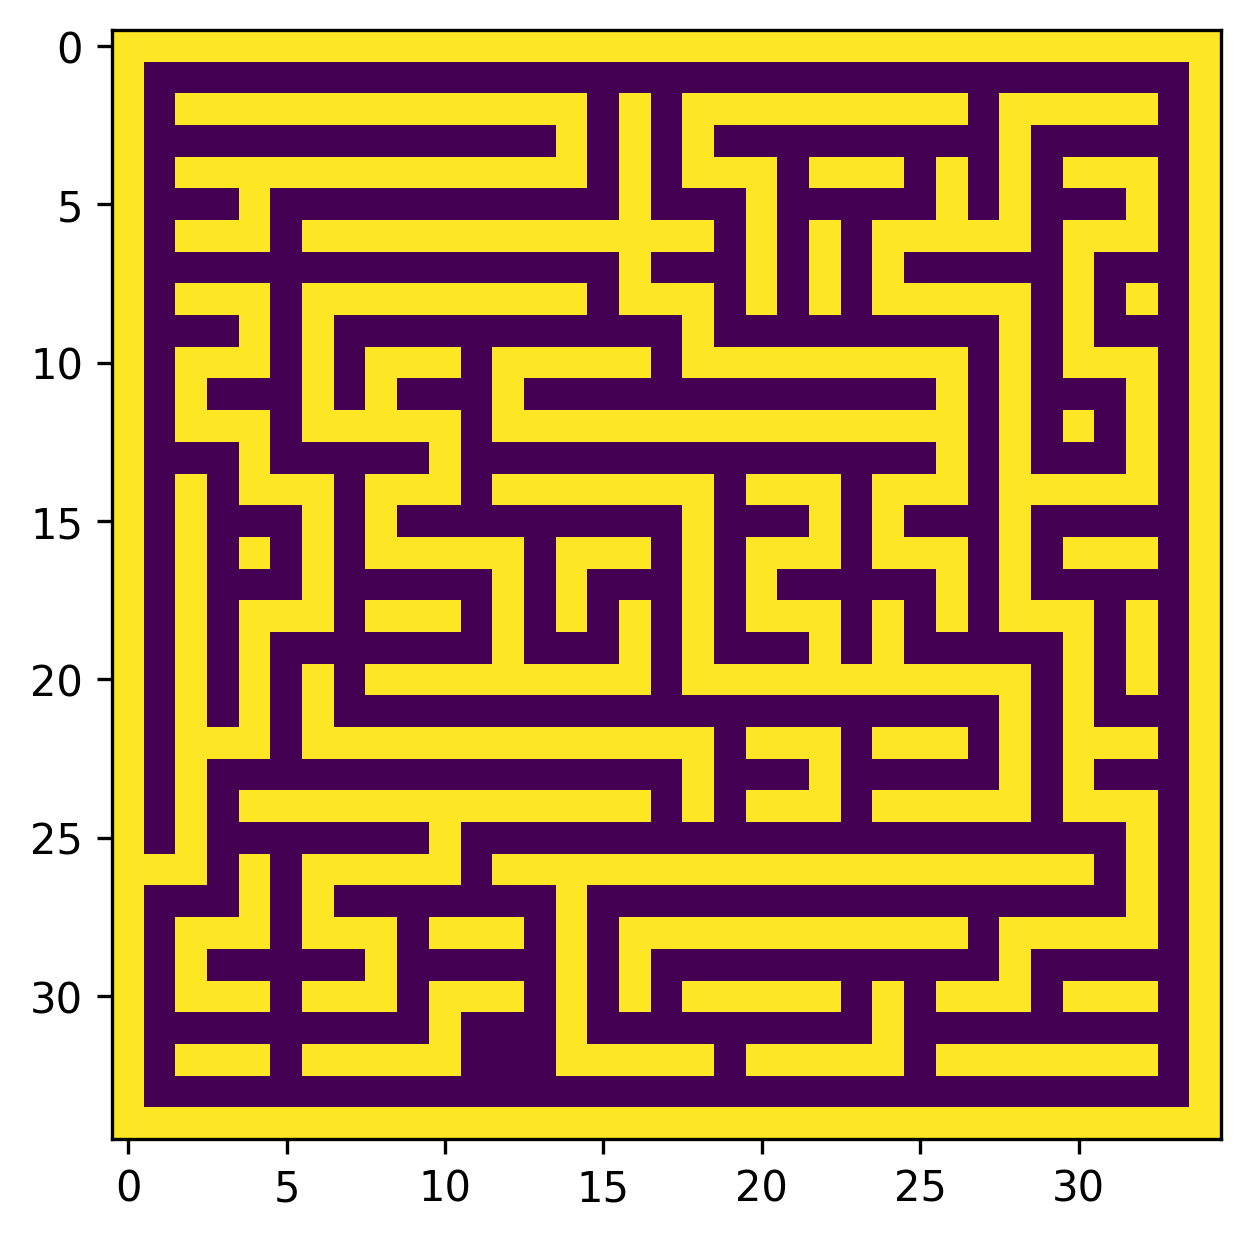

In [ ]:
plt.imshow(maze(width=35,height=35))
plt.show()

## Do a little random walk inside the maze

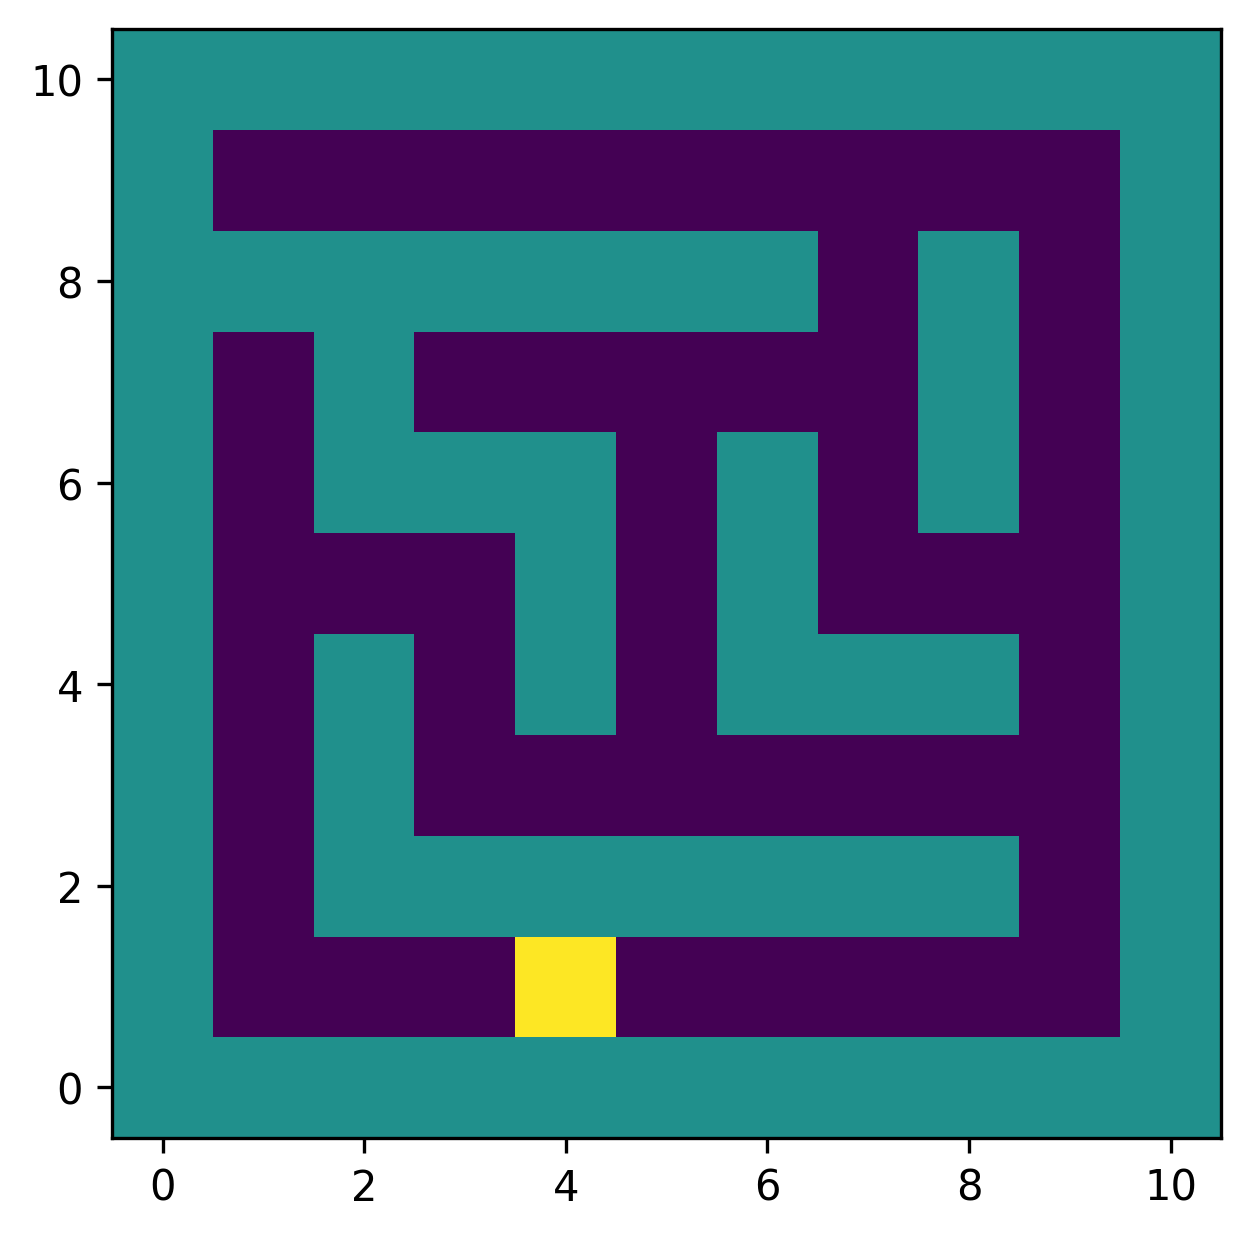

In [ ]:
# make a maze, convert array from True/False to integer:
world=np.array(maze(width=11,height=11),dtype='int')

# the four directions of motion [delta_jx,delta_jy]:
directions=np.array([[0,1],[0,-1],[1,0],[-1,0]])

# initial position
jx,jy=1,1

# take a random walk through the maze and animate this!
nsteps=40
for j in range(nsteps):
    # make a random step
    pick=np.random.randint(4)
    jx_new,jy_new=np.array([jx,jy])+directions[pick]
    if world[jx_new,jy_new]==0: # is empty, can move!
        jx,jy=jx_new,jy_new
        # show what's happening
        picture=np.copy(world) # copy the array (!)
        picture[jx,jy]=2
        plt.imshow(picture,origin='lower')
        plt.show()
        sleep(0.01)
        clear_output(wait=True)

## Now: policy gradient

$$\delta\theta = \eta R \sum_{s,a} {\partial \over \partial \theta} \ln \pi_{\theta}(s,a)$$

Here $\theta$ stands for the parameters controlling the policy probabilities $\pi_{\theta}(s,a)$, s is the state, a the action, and the sum runs over all state-action pairs that were encountered in the given trajectory, which led to an overall return (sum of rewards) R.

Let's do a softmax-type parametrization:

So: $$\theta=(z_0,z_1,z_2,z_3)$$ and

$$\pi_{\theta}(s,a=j) = {e^{z_j} \over \sum_k e^{z_k}} $$

...where in reality the $z_j$ of course also depend on the state s, but for brevity we did not display that dependence here. They will all be stored in arrays, of the size of the maze!

So, we get:

$$ {\partial \over \partial z_l} \ln \pi_{\theta}(s,a=j) = \delta_{l,j}-\pi_{\theta}(s,a=l) $$


In [ ]:
np.cumsum([0.1,0.3,0.4,0.2]) # cumulative sum, will be useful!
# this is useful for drawing integer random numbers according
# to a given arbitrary probability distribution!
# just draw a uniformly distributed number p between 0 and 1 and then
# check successively whether p<(entry of cumsum); stop when
# this is first fulfilled! The index of the entry where you
# stopped will be randomly distributed according to the
# distribution given in the original array.

array([0.1, 0.4, 0.8, 1. ])

## The policy gradient algorithm

In 124 lines of pure python code, including visualization and comments

In [ ]:
# full policy gradient RL for picking up 'treasure chests'
# in an automatically generated maze; 2020 by F.M.

M=11 # the size of the world: M x M
eta=0.01 # the learning rate
num_chests=10 # maximum number of treasure chests

# make a maze, convert array from True/False to integer:
world=np.array(maze(width=M,height=M),dtype='int')

# the four directions of motion [delta_jx,delta_jy]:
directions=np.array([[0,1],[0,-1],[1,0],[-1,0]])

# the policy probabilities as an array policy[state,action]
# here the state is represented by two coordinates jx,jy
policy=np.full([M,M,4],0.25)
# and also the underlying 'z'-values for the
# softmax parametrization:
policy_z=np.full([M,M,4],0.0)

# steps inside one trajectory
nsteps=80

# total number of trials, i.e. trajectories
ntrials=1000
skipsteps=5 # don't plot every trial

# storing all the state/action pairs of the current trajectory
states=np.zeros([nsteps,2], dtype='int')
actions=np.zeros(nsteps, dtype='int')

# a map of rewards (the 'boxes' are here!)
reward=np.zeros([M,M])

# storing all the returns, for all trials:
Returns=np.zeros(ntrials)

# try random selection of reward sites (treasure chests)
for n in range(10):
    jx_target,jy_target=np.random.randint(M,size=2)
    if jx_target>4 or jy_target>4: # stay away from starting point!
        if world[jx_target,jy_target]==0: # empty, keep it!
            reward[jx_target,jy_target]+=1

# try many trajectories:
for trial in range(ntrials):

    # set return to zero for this trajectory:
    R=0
    # initial position:
    jx,jy=1,1

    # go through all time steps
    for t in range(nsteps):
        # make a random step, according to the policy distribution
        p=np.random.uniform()
        cumulative_distribution=np.cumsum(policy[jx,jy,:])
        for pick in range(4):
            if p<cumulative_distribution[pick]:
                break

        # record the move
        states[t,0]=jx
        states[t,1]=jy
        actions[t]=pick

        # now make the move
        jx_new,jy_new=np.array([jx,jy])+directions[pick]

        # really make it if there is no wall:
        if world[jx_new,jy_new]==0: # is empty, can move!
            jx,jy=jx_new,jy_new

        # get a reward if on a treasure chest!
        r=reward[jx,jy]
        R+=r

    # store the return
    Returns[trial]=R

    # use policy gradient update rule to adjust
    # probabilities!
    for t in range(nsteps): # go through the trajectory again
        a=actions[t] # remember the action taken at step t
        sx=states[t,0] # state/x-position at step
        sy=states[t,1] # state/y-position
        kronecker=np.zeros(4); kronecker[a]=1.0
        policy_z[sx,sy,:]+=eta*R*(kronecker-policy[sx,sy,:])

    # now calculate (again) the policy probab. from the z-values
    policy=np.exp(policy_z)
    policy/=np.sum(policy,axis=2)[:,:,None] # normalize
    # these two steps together implement softmax on every
    # site! efficient array syntax!

    # visualize!
    if trial%skipsteps==0 or trial==ntrials-1:
        # show what's happened in this trajectory
        clear_output(wait=True)
        fig,ax=plt.subplots(ncols=2,nrows=2,figsize=(7,7))
        ax[0,0].plot(Returns) # all the returns, in all trials
        ax[0,0].set_title("Return vs. trial")

        picture=np.zeros([M,M,3]) # last index: red/green/blue
        picture[:,:,0]=world # walls are red
        for j in range(nsteps): # highlight trajectory
            picture[states[j,0],states[j,1],1]=0.5*(1.0+(1.0*j)/nsteps)
        # put a bright pixel at the positions visited
        picture[:,:,2]+=0.5*reward # highlight the target sites!
        picture[:,:,0]+=0.5*reward

        # show picture (transpose is needed because
        # otherwise the first coordinate jx is plotted upwards,
        # not to the right)
        ax[0,1].imshow(np.transpose(picture,[1,0,2]),origin='lower')
        ax[0,1].axis('off')

        ax[1,0].imshow(np.transpose(policy[:,:,0]),origin='lower')
        ax[1,0].axis('off')
        ax[1,0].set_title("prob(move up)")
        ax[1,1].imshow(np.transpose(policy[:,:,2]),origin='lower')
        ax[1,1].set_title("prob(move right)")
        ax[1,1].axis('off')
        plt.show()

KeyboardInterrupt: 

# Tutorial Exercise: Change the algorithm, such that the treasure chests are 'taken away' by the robot

That is: the reward value at a given site should decrease every time the reward is received (but you need to re-initialize to the old reward map for every new trial!)

Observe how the strategy looks like now!

Attention: don't go to negative rewards! (unless you want to train the robot to avoid places after it picked up a chest there!)

In [11]:
###settings
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

# Coordinates use (x, y) as the first and second NumPy indices.
DIRECTIONS = np.array([[0, 1], [0, -1], [1, 0], [-1, 0]])


def maze(width=81, height=51, complexity=.75, density=.75):
    # Maze generation algorithm from Wikipedia (user-provided version).
    # Only odd shapes
    shape = ((height // 2) * 2 + 1, (width // 2) * 2 + 1)
    complexity = int(complexity * (5 * (shape[0] + shape[1])))
    density = int(density * ((shape[0] // 2) * (shape[1] // 2)))
    Z = np.zeros(shape, dtype=bool)
    Z[0, :] = Z[-1, :] = 1
    Z[:, 0] = Z[:, -1] = 1
    for i in range(density):
        x, y = np.random.randint(0, shape[1] // 2) * 2, np.random.randint(0, shape[0] // 2) * 2
        Z[y, x] = 1
        for j in range(complexity):
            neighbours = []
            if x > 1: neighbours.append((y, x - 2))
            if x < shape[1] - 2: neighbours.append((y, x + 2))
            if y > 1: neighbours.append((y - 2, x))
            if y < shape[0] - 2: neighbours.append((y + 2, x))
            if len(neighbours):
                # randint(len(neighbours)) includes the final neighbor.
                # The original pasted code used len(neighbours)-1, an off-by-one bug.
                y_, x_ = neighbours[np.random.randint(0, len(neighbours))]
                if Z[y_, x_] == 0:
                    Z[y_, x_] = 1
                    Z[y_ + (y - y_) // 2, x_ + (x - x_) // 2] = 1
                    x, y = x_, y_
    return Z


def make_maze(M=11, seed=7):
    # Seed the Wikipedia generator without changing the RNG state used for RL.
    saved = np.random.get_state()
    try:
        np.random.seed(seed)
        return maze(width=M, height=M).astype(int)
    finally:
        np.random.set_state(saved)


def reachable(world, start):
    """Cells in the connected component containing start."""
    seen = {start}
    queue = deque([start])
    while queue:
        x, y = queue.popleft()
        for dx, dy in DIRECTIONS:
            q = (int(x+dx), int(y+dy))
            if (0 <= q[0] < world.shape[0] and 0 <= q[1] < world.shape[1]
                    and world[q] == 0 and q not in seen):
                seen.add(q)
                queue.append(q)
    return seen


def shortest_distances(world, start):
    distance = {start: 0}
    queue = deque([start])
    while queue:
        cur = queue.popleft()
        for d in DIRECTIONS:
            nxt = (cur[0]+int(d[0]), cur[1]+int(d[1]))
            if (0 <= nxt[0] < world.shape[0] and 0 <= nxt[1] < world.shape[1]
                    and world[nxt] == 0 and nxt not in distance):
                distance[nxt] = distance[cur]+1
                queue.append(nxt)
    return distance


def softmax(logits):
    # Numerically stable softmax across the four action values.
    z = logits - np.max(logits, axis=-1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=-1, keepdims=True)


def next_position(world, pos, action, door=None, has_key=False):
    dx, dy = DIRECTIONS[action]
    nx, ny = int(pos[0] + dx), int(pos[1] + dy)
    if not (0 <= nx < world.shape[0] and 0 <= ny < world.shape[1]):
        return pos
    if world[nx, ny] == 1:
        return pos
    if door is not None and (nx, ny) == door and not has_key:
        return pos
    return (nx, ny)


def moving_average(values, window=100):
    # Same-length curve; average available values near the beginning.
    cs = np.r_[0, np.cumsum(values)]
    return np.array([(cs[i+1]-cs[max(0, i+1-window)]) / min(i+1, window)
                     for i in range(len(values))])


def plot_result(world, returns, path, title, treasures=None, key=None,
                door=None, goal=None, policy=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ax[0].plot(returns, alpha=.20, label='Episode return')
    ax[0].plot(moving_average(returns), linewidth=2, label='Moving average (100)')
    ax[0].set(xlabel='Training episode', ylabel='Return', title=title)
    ax[0].legend()
    ax[1].imshow(world.T, origin='lower', cmap='Greys', vmin=0, vmax=1)
    if treasures is not None:
        xs, ys = np.nonzero(treasures > 0)
        ax[1].scatter(xs, ys, c='gold', s=85, marker='s', label='Treasure')
    for point, label, marker, color in [(key, 'Key', 'P', 'orange'),
                                       (door, 'Door', 's', 'red'),
                                       (goal, 'Goal', '*', 'green')]:
        if point is not None:
            ax[1].scatter(*point, s=150, marker=marker, c=color, label=label)
    if path:
        x, y = np.asarray(path).T
        ax[1].plot(x, y, '-o', color='tab:blue', lw=1.5, markersize=2, alpha=.75)
        ax[1].scatter(x[0], y[0], c='lime', s=95, edgecolors='black', label='Start')
    ax[1].set(xlim=(-.5, world.shape[0]-.5), ylim=(-.5, world.shape[1]-.5),
              title='Example trajectory after training', xlabel='x', ylabel='y')
    ax[1].legend(loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()


def update_reinforce(logits, policy, states, actions, rewards, eta, baseline=0.0):
    """REINFORCE with reward-to-go. No network; logits are a state-action table.

    Unlike the original tutorial's one total R for every step, this uses
    G_t=sum of rewards from t onward, reducing noise for delayed rewards.
    baseline is optional and kept at zero for transparency.
    """
    returns_to_go = np.cumsum(np.asarray(rewards, dtype=float)[::-1])[::-1]
    grad = np.zeros_like(logits)
    for state, a, G in zip(states, actions, returns_to_go):
        indicator = np.zeros(4)
        indicator[a] = 1.0
        grad[state] += (G-baseline) * (indicator - policy[state])
    logits += eta * grad
    return softmax(logits)


Exercise 1 — collected 10/10 chests in sample episode
Mean return: first 100 = 0.91 | last 100 = 9.67


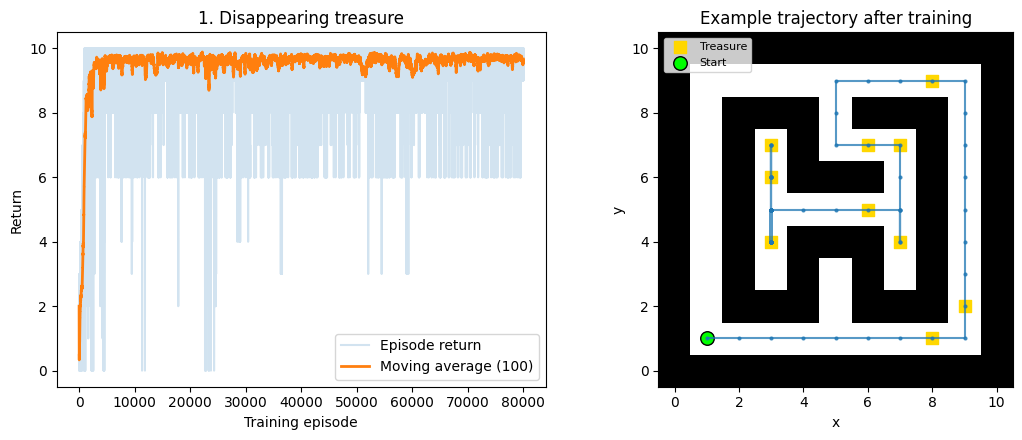

In [16]:
# EXERCISE 1 — Treasure is removed after the first collection each episode
rng = np.random.default_rng(10)
M = 11
world = make_maze(M, seed=12)
start = (1, 1)
free = sorted(p for p in reachable(world, start)
              if p != start and sum(p) >= 7)
num_chests = min(10, len(free))
chosen = rng.choice(len(free), size=num_chests, replace=False)
reward = np.zeros((M, M))
for i in chosen:
    reward[free[i]] = 1.0

ntrials = 80000
nsteps = 80
eta = 0.015
policy_z = np.zeros((M, M, 4))
policy = softmax(policy_z)
Returns = np.zeros(ntrials)

for trial in range(ntrials):
    reward_trial = reward.copy()  # RESTORE treasure at the start of each episode
    pos = start
    states, actions, rewards = [], [], []
    for t in range(nsteps):
        a = int(rng.choice(4, p=policy[pos]))
        states.append(pos)
        actions.append(a)
        pos = next_position(world, pos, a)
        r = reward_trial[pos]
        rewards.append(r)
        reward_trial[pos] = max(0.0, reward_trial[pos] - 1.0)  # collected!
    Returns[trial] = sum(rewards)
    policy = update_reinforce(policy_z, policy, states, actions, rewards, eta)

# Sample a trajectory with the final policy (no further learning)
pos = start
path = [pos]
reward_trial = reward.copy()
collected = 0
for t in range(nsteps):
    a = int(rng.choice(4, p=policy[pos]))
    pos = next_position(world, pos, a)
    path.append(pos)
    collected += reward_trial[pos]
    reward_trial[pos] = 0.0
print(f'Exercise 1 — collected {int(collected)}/{num_chests} chests in sample episode')
print('Mean return: first 100 =', round(Returns[:100].mean(), 2),
      '| last 100 =', round(Returns[-100:].mean(), 2))
plot_result(world, Returns, path, '1. Disappearing treasure', treasures=reward)


# Tutorial Exercise: Think about other rules of the game!

The only constraint is that the best (or at least a good) strategy can be formulated based only on the position (e.g. wandering ghosts like in PacMan would be a problem for the robot)

## Exercise 2: New rules using only position
The robot must reach a fixed goal and gets a small per-step penalty. Because the board and goal stay fixed, `(x,y)` is enough to define the state.

Exercise 2 — goal: (1, 11) | greedy rollout reaches goal: False
Success rate: first 100 = 0.0 | last 100 = 0.0


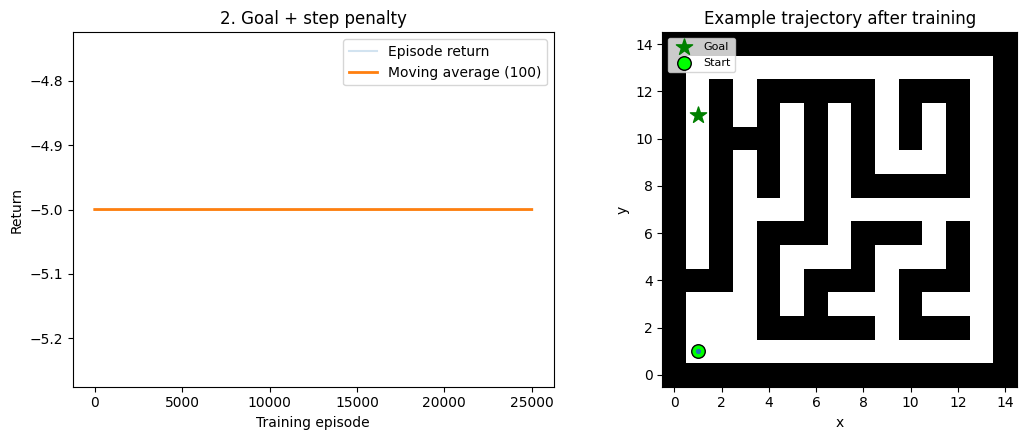

In [33]:
# EXERCISE 2 — Invent new rules, while the state remains ONLY (x, y).
# Rules: reward +30 for reaching a fixed goal; penalty -0.05 per move;
# end the episode when the goal is reached. The goal and walls never change.
rng = np.random.default_rng(20)
M = 15
world = make_maze(M, seed=23)
start = (1, 1)
world[start] = 0
# Only choose a goal connected to the start; a nearby one is easier to learn.
distances = shortest_distances(world, start)
candidates = [p for p, d in distances.items()
              if d >= 15 and p != start]

goal = candidates[rng.integers(len(candidates))]

ntrials = 25000
nsteps = 100
eta = 0.015
policy_z = np.zeros((M, M, 4))
policy = softmax(policy_z)
Returns = np.zeros(ntrials)
successes = np.zeros(ntrials)

for trial in range(ntrials):
    pos = start
    states, actions, rewards = [], [], []
    for t in range(nsteps):
        a = int(rng.choice(4, p=policy[pos]))
        states.append(pos)
        actions.append(a)
        pos = next_position(world, pos, a)
        reached_goal = (pos == goal)
        rewards.append(30.0 if reached_goal else -0.05)
        if reached_goal:
            successes[trial] = 1
            break
    Returns[trial] = sum(rewards)
    policy = update_reinforce(policy_z, policy, states, actions, rewards, eta)

pos = start
path = [pos]
for t in range(nsteps):
    a = int(np.argmax(policy[pos]))  # greedy evaluation after training
    pos = next_position(world, pos, a)
    path.append(pos)
    if pos == goal:
        break
print('Exercise 2 — goal:', goal, '| greedy rollout reaches goal:', pos == goal)
print('Success rate: first 100 =', round(successes[:100].mean(), 2),
      '| last 100 =', round(successes[-100:].mean(), 2))
plot_result(world, Returns, path, '2. Goal + step penalty', goal=goal)


# Homework Exercise: Invent a game where the state needs to contain additional information (rather than just the position jx,jy)!

...but in such a way that it can still be handled with a table.

The key changes what movements are possible, so `(x,y)` is insufficient. State is `(x,y,has_key)` and the policy has shape `(11,11,2,4)`.

Exercise 3 — greedy rollout reaches goal with key: False
Success rate: first 100 = 0.0 | last 100 = 0.0
Policy table shape: (15, 15, 2, 4) = (x, y, has_key, action)


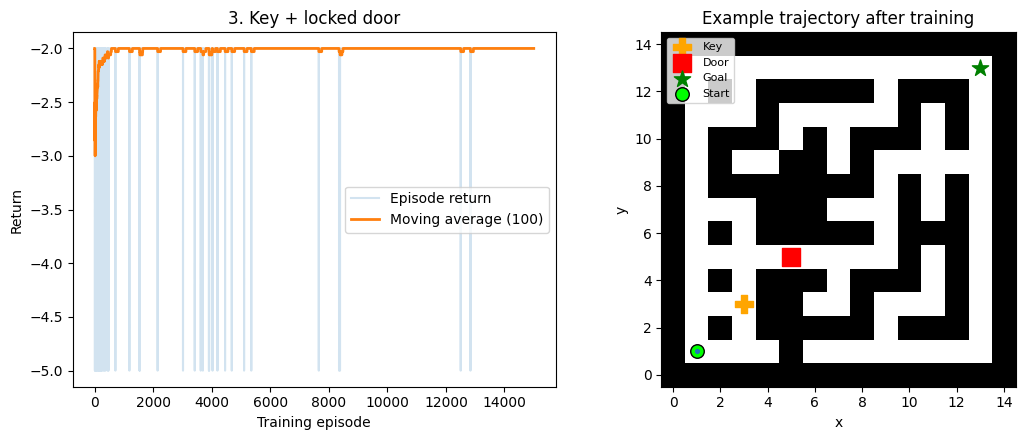

In [66]:
# EXERCISE 3 — State is now (x, y, has_key), not just (x, y).
# A locked door divides the board. The robot must fetch the key, cross the
# doorway, and reach the goal. This remains a TABLE-based policy gradient.
rng = np.random.default_rng(20)
M = 15
world = make_maze(M, seed=16789)
# Divide the generated maze into two areas with a locked doorway.
# Carve a short guaranteed traversable passage connecting the puzzle pieces;
# all other walls retain their randomly generated Wikipedia-maze layout.
door = (5, 5)
world[5, 1:10] = 1     # locked barrier across the maze
world[door] = 0       # traversable only with the key
world[1:10, 5] = 0    # horizontal corridor to the door
world[1, 1:6] = 0     # start to the corridor
world[1:4, 3] = 0     # alcove containing the key
world[9, 5:8] = 0     # goal alcove
start = (1, 1)
key_location = (3, 3)
goal = (13, 13)

ntrials = 15000
nsteps = 100
eta = 0.01
policy_z = np.zeros((M, M, 2, 4))  # 2 possibilities for has_key
policy = softmax(policy_z)
Returns = np.zeros(ntrials)
successes = np.zeros(ntrials)

for trial in range(ntrials):
    pos = start
    has_key = 0
    states, actions, rewards = [], [], []
    for t in range(nsteps):
        state = (pos[0], pos[1], has_key)
        a = int(rng.choice(4, p=policy[state]))
        states.append(state)
        actions.append(a)
        pos = next_position(world, pos, a, door=door, has_key=bool(has_key))
        r = -0.05
        if pos == key_location and not has_key:
            has_key = 1
            r += 3.0
        if pos == goal and has_key:
            r += 30.0
            successes[trial] = 1
            rewards.append(r)
            break
        rewards.append(r)
    Returns[trial] = sum(rewards)
    policy = update_reinforce(policy_z, policy, states, actions, rewards, eta)

# Greedy path under the learned policy
pos, has_key = start, 0
path = [pos]
for t in range(nsteps):
    a = int(np.argmax(policy[pos[0], pos[1], has_key]))
    pos = next_position(world, pos, a, door=door, has_key=bool(has_key))
    if pos == key_location:
        has_key = 1
    path.append(pos)
    if pos == goal and has_key:
        break
print('Exercise 3 — greedy rollout reaches goal with key:', pos == goal and bool(has_key))
print('Success rate: first 100 =', round(successes[:100].mean(), 2),
      '| last 100 =', round(successes[-100:].mean(), 2))
print('Policy table shape:', policy.shape, '= (x, y, has_key, action)')
plot_result(world, Returns, path, '3. Key + locked door', key=key_location,
            door=door, goal=goal)


In [59]:
#np.random.seed(20)
#print(np.random.random())


0.5881308010772742
